# DOE-028
## MA1 / MA2 の傾き算出機能の動作確認

- 対象銘柄: 9984
- 実験パラメータ
    - TYPE_MA_1
        - PPF, SMA, EMA, WMA
- 固定パラメータ
    - PERIOD_MA_1
        - PPF
            - 5
            - 他のパラメータ
                - GAIN_MA_1 = 0.05 / GAIN_PREDICT_MA_1 = 0.5
        - SMA, EMA, WMA
            - 90
    - PERIOD_MA_2（長周期移動平均線）
        - 1350
    - FLAG_SLOPE（毎回傾きを算出するかどうかのフラグ）
        - True
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-028"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
]

# CSV ファイルを読み込んで結合
"""
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)
"""
"""
df = pd.concat(
    [
        pd.read_csv(file).assign(FILENAME=Path(file).name)
        for file in list_csv_file
    ],
    ignore_index=True,
)

# FILENAME を先頭列に移動
#df = df[["FILENAME"] + [col for col in df.columns if col != "FILENAME"]]
"""

df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\n*** Past", len(list_csv_file), "days statistics ***")
print("\nSummary Statistics")
print(df_total)
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

    TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  FLAG_SLOPE  Profit  Transactions       DATE
0         PPF            5         1350        True    69.0          34.0 2026-09-01
1         SMA           90         1350        True  -101.0          24.0 2026-09-01
2         EMA           90         1350        True    84.0          20.0 2026-09-01
3         WMA           90         1350        True    73.0          22.0 2026-09-01
4         PPF            5         1350        True  -145.0          48.0 2026-09-02
..        ...          ...          ...         ...     ...           ...        ...
99        WMA           90         1350        True   -34.0          12.0 2026-10-08
100       PPF            5         1350        True   168.0          12.0 2026-10-09
101       SMA           90         1350        True   187.0           8.0 2026-10-09
102       EMA           90         1350        True   181.0           6.0 2026-10-09
103       WMA           90         1350        True   194.0      

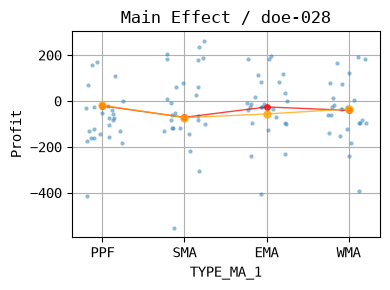

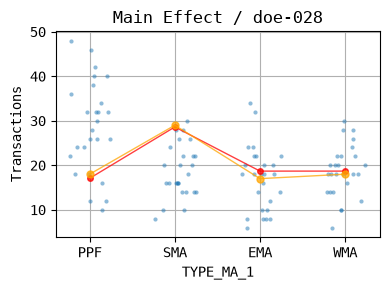

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
#plt.rcParams["font.size"] = 11

cols_param = [
    "TYPE_MA_1",
]


for name_y in ["Profit", "Transactions"]:
    fig, ax = plt.subplots(1, 1, figsize=(4, 3))

    # for ax, col in zip(axes.flatten(), cols_param):
    col = cols_param[0]
    sns.stripplot(
        data=df,
        x=col,
        y=name_y,
        ax=ax,
        size=3,
        jitter=0.25,  # 横方向へのばらつき具合
        alpha=0.5,  # 重なりが見やすいよう少し透明に
        color="tab:blue",  # 散布図の色を指定
    )

    # x の各水準ごとの平均値
    mean = df.groupby(col)[name_y].mean()
    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    ax.plot(
        range(len(mean)),
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
        alpha=0.75,
        zorder=5,  # 点の裏に隠れないよう前面に描画
    )

    # x の各水準ごとのメジアン
    median = df.groupby(col)[name_y].median()
    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    ax.plot(
        range(len(median)),
        median.values,
        "o-",
        color="orange",
        markersize=5,
        linewidth=1,
        alpha=0.75,
        zorder=5,
    )

    ax.set(xlabel=col, ylabel=name_y)
    ax.grid(True)

    ax.set_title(f"Main Effect / {name_doe}")
    # fig.suptitle(f"Main Effect / {name_doe}", fontsize=9)

    plt.tight_layout()
    pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()

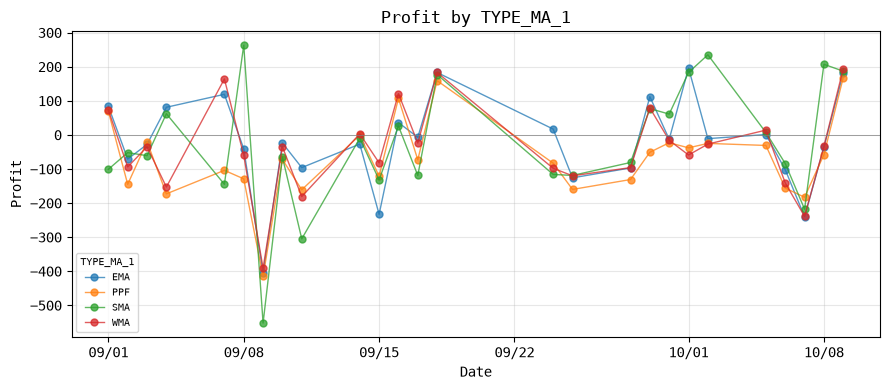

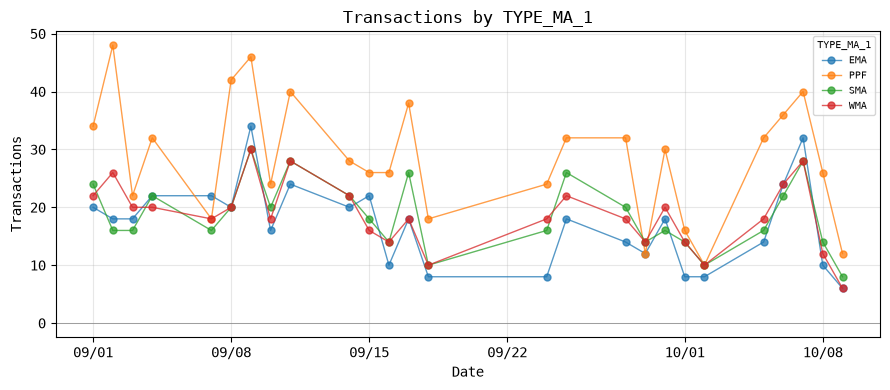

In [12]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "monospace"


for name_y in ["Profit", "Transactions"]:
    fig, ax = plt.subplots(figsize=(9, 4))
    for name, group in df.groupby("TYPE_MA_1"):
        group = group.sort_values("DATE")
        ax.plot(
            group["DATE"],
            group[name_y],
            marker="o",
            markersize=5,
            linewidth=1,
            alpha=0.75,
            label=name,
        )
    
    ax.tick_params(axis="x", labelrotation=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
    ax.axhline(0, color="gray", linewidth=0.5, linestyle="solid")
    
    ax.set_xlabel("Date")
    ax.set_ylabel(name_y)
    ax.set_title(f"{name_y} by TYPE_MA_1")
    
    ax.legend(title="TYPE_MA_1", fontsize=7, title_fontsize=7)
    ax.grid(True, alpha=0.3)
    
    fig.tight_layout()
    pngfile = f"../doe/{name_doe}/trend_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()